# Introduction

  This routine calculates variations of predicted quantities of interest, from a set of available Solar Models (see the ReadMe file), with respect to desired input variations in variables such as nuclear reaction rates  solar composition, and other solar parameters (See the **Input variations** section).

  Predicted quantities include: neutrino fluxes from different sources (_pp, pep, hep, 7Be, 8B, 13N, 15O, 17F_), surface He mass fraction (_Ys_) and the location of the base of the convective envelope in units of solar radius (_Rcz_). Sound speed (_Cs_) profile variations (`var_`) are also calculated. The resulting new _Cs_ profiles (`prof_`) and their normalized deviations in terms of the actual solar _Cs_ profile (`delta_`) are also computed.

  All results are saved in the "_RESULTS_" subdirectory in ASCII table format.
Plots for the aforementioned _Cs_ variations and deviations are saved in PDF format.
Output file names may be customized in the **Options** section.


Code developed by Y. Herrera (herrera@ice.csic.es),
Institute of Space Sciences (ICE-CSIC),
Barcelona, Spain.

In [1]:
### INTRODUCTION {{{

    #   This routine calculates variations of predicted quantities of interest,
    # from a set of available Solar Models (see the ReadMe file), with respect to 
    # desired input variations in variables such as nuclear reaction rates,
    # solar composition, and other solar parameters (See INPUT section).

    #   Predicted quantities include: neutrino fluxes from different
    # sources (pp, pep, hep, 7Be, 8B, 13N, 15O, 17F), surface He mass fraction
    # (Ys) and the location of the base of the convective envelope in units
    # of solar radius (Rcz).

    #   Sound speed (Cs) profile variations are also calculated. The resulting
    # new Cs profiles and their normalized deviations in terms of the actual
    # solar Cs profile are also computed.

    #   All results are saved in the "RESULTS" subdirectory in ASCII table format.
    # Plots for aforementioned Cs variations and deviations are saved in PDF format.
    # Output file names may be customized in the OPTIONS section.

    # Developed by Y. Herrera (herrera@ice.csic.es), at
    # Institute of Space Sciences (ICE-CSIC)

### }}}

### Prerequisites

This Jupyter notebook requires ___IRkernel___ installed. You may follow the instructions on how to install it at: https://irkernel.github.io/installation.


A standalone ___R___ script version of this code is also provided in this package, which only requires the basic ___R___ installation.


# Options
You may change these options to suit your convenience.
All result files are written to the "_RESULTS_" subdirectory.


In [2]:
### OPTIONS {{{

# Resulting neutrino generation rates, Ys, and Rcz are saved in:
output_file_nu <- "nu_fluxes_new.dat"

# Resulting Cs new profiles ("prof_" preffix), variations ("var_" preffix),
# and deviations from solar ones ("delta_" preffix) are saved in files ending in:
output_file_Cs <- "Csound_new.dat"

# Plots are saved to:
plot_file <- "Plots_Csound_new.pdf"


# Formatting and other options
options(
	digits = 6    ,
	show.error.messages = FALSE   ,
	show.warnings = FALSE
    )
colwidth <- getOption("digits")+6

### }}}


# Input Variations
Variations of Solar models parameters (in dex). Change these to your desired input values. Do not change the order !!

In [3]:
### INPUT: {{{
# Variations from Solar models parameters (in dex). Do not change the order !!

input_variations <- c(
    # Nuclear reactions S-factors
    "S11"	= 0.0   ,    
    "S33"	= 0.0   ,
    "S34"	= 0.0   ,
    "Se7"	= 0.0   ,
    "S17"	= 0.0   ,
    "Shep"	= 0.0   ,
    "S114"	= 0.0   ,
    "S116"	= 0.0   ,
    # Other solar parameters
    "Age"	= 0.0   ,    # Solar age
    "Diff"	= 0.0   ,    # Diffusion coefficient
    "Lumi"	= 0.0   ,    # Solar luminosity
    "OpacA"	= 0.0   ,    # Opacity factor (inner)
    "OpacB"	= 0.0   ,    # Opacity factor (outter)
    # Elements abundances 
     "C"	= 0.2   ,
     "N"	= 0.0   ,
     "O"	= 0.0   ,
     "Ne"	= 0.0   ,
     "Mg"	= 0.0   ,
     "Si"	= 0.0   ,
     "S"	= 0.0   ,
     "Ar"	= 0.0   ,
     "Fe"	= 0.0
    )
### }}}

# Processing
### No further user input required from this point

In [4]:
### MODELS DATA: {{{
    ### Neutrino generation and variables initialization.
    #  Model           nu_pp    nu_pep   nu_hep   nu_7Be   nu_8B    nu_13N   nu_15O   nu_17F   Ys             Rcz
    SF3_AAG21m  <-  c( 6.00e10, 1.447e8, 8160.95, 4.517e9, 4308688, 2.221e8, 1.577e8, 3401173, 0.23467429e+00, 0.7188408371 )
    SF3_AGSS09m <-  c( 6.01e10, 1.451e8, 8215.66, 4.429e9, 4135059, 2.052e8, 1.447e8, 3290205, 0.23200218e+00, 0.7221316935 )
    SF3_C11     <-  c( 5.99e10, 1.441e8, 8098.32, 4.603e9, 4483892, 2.480e8, 1.776e8, 4135844, 0.23683168e+00, 0.7154190607 )
    SF3_GS98    <-  c( 5.96e10, 1.425e8, 7949.66, 4.854e9, 5024799, 2.795e8, 2.067e8, 5349739, 0.24293369e+00, 0.7111655734 )
    SF3_MB22m   <-  c( 5.95e10, 1.422e8, 7921.61, 4.899e9, 5127029, 3.118e8, 2.322e8, 4737512, 0.24431846e+00, 0.7113853858 )
    SF3_MB22p   <-  c( 5.95e10, 1.422e8, 7933.73, 4.875e9, 5073959, 3.102e8, 2.304e8, 4698527, 0.24369318e+00, 0.7116922929 )

    models_data <- cbind(
        "GS98"   =  SF3_GS98    ,
        "AGSS09" =  SF3_AGSS09m ,
        "C11"    =  SF3_C11     ,
        "AAG21"  =  SF3_AAG21m  ,
        "MB22m"  =  SF3_MB22m   ,
        "MB22p"  =  SF3_MB22p
    )
    nu_var <- models_data
    nu_var[] <- NA
    nu_new <- models_data
    nu_new[] <- NA

    ### Read Solar sound speed profile.
    Cs_obs_data <- read.table("SolarModels/Cs_obs.dat", comment.char="#", header=FALSE,
        col.names= c("R_sun", "c", "sigma_c", "R_sun2", "rho","sigma_rho")
        )

### }}}

In [5]:
### CALCULATIONS {{{

### Loop over available Solar compositions.
for (compo in colnames(models_data)) {

	compo_key <- compo
	if ( compo == "MB22p" || compo == "MB22m" ) { compo_key <- "MB22" }

    ### Load Partial Logarithmic Derivatives of neutrino generation.
	pwrlaw_file <- paste("PLD/pwrlaws_SF3_",tolower(compo_key),".dat",sep="")
	if ( ! file.exists(pwrlaw_file) ) {
	    message(paste(" PLD file not found:", pwrlaw_file))
	    next
	}
	pwrlaw_matrix <- read.table(pwrlaw_file, comment.char="#", header=FALSE, row.names=1+length(input_variations) )
	names(pwrlaw_matrix) <- names(input_variations)

    ### Calculate variations of neutrino generation.
	nu_var[,compo] <- as.matrix(pwrlaw_matrix) %*% input_variations


    ### Load Partial Logarithmic Derivatives of sound speed profile.
	dlc_dlz_file <- paste("PLD/dlnc_dlnz_",tolower(compo),".dat",sep="")
	if ( ! file.exists(dlc_dlz_file) ) {
	    message(paste(" PLD file not found:", dlc_dlz_file))
	    next
	}
	dlc_dlz_data <- read.table(dlc_dlz_file, comment.char="#", header=FALSE)
	names(dlc_dlz_data)  <- read.table(dlc_dlz_file, stringsAsFactors=FALSE,comment.char="",nrows=1,skip=1)[,-1];
	dlc_dlz_cols <- names(dlc_dlz_data)


    ### Calculate new Cs variations conforming to PLD data.
	if ( ! exists("Cs_var") ) {
	    Cs_var <- data.frame( "R_sun"=dlc_dlz_data$Radius )
	}
	dlc_input_common <- dlc_dlz_cols[dlc_dlz_cols %in% names(input_variations)]
	Cs_var[,compo] <- as.matrix(dlc_dlz_data[,dlc_input_common]) %*% input_variations[dlc_input_common]


    ### Load Cs profile from corresponding structure file.
	struct_file <- (paste("SolarModels/struct+nu_SF3_",compo,".dat",sep=""))
	if ( ! file.exists(struct_file) ) {
	    message(paste(" Structure file not found:", struct_file))
	    next
	}
	struct_data <- read.table(struct_file, comment.char="#", header=FALSE)
	names(struct_data)   <- read.table(struct_file, stringsAsFactors=FALSE,comment.char="",nrows=1)[,-1];


    ### Calculate Cs new profile for current composition.
	if ( ! exists("Cs_new_prof") ) {
	    Cs_new_prof <- data.frame( "R_sun"=struct_data$R_sun)
	}

	### Interpolate Cs variation in struct grid and add to Cs profile
	Cs_new_prof[,compo] <- spline(x=Cs_var[,"R_sun"], y=Cs_var[,compo], xout=Cs_new_prof[,"R_sun"], method="natural")[2]
	Cs_new_prof[,compo] <- struct_data[,"Csound"] * 10^(Cs_new_prof[,compo])


    ### Calculate Cs profile deviation from solar for current composition.
	if ( ! exists("Cs_deltas") ) {
	    Cs_deltas <- data.frame( "R_sun"=struct_data$R_sun)
	}

	### Interpolate Cs solar profile in struct grid and calculate delta.
	Cs_deltas[,compo] <- spline(x=Cs_obs_data[,"R_sun"], y=Cs_obs_data[,"c"], xout=Cs_deltas[,"R_sun"], method="natural")[2]
	Cs_deltas[,compo] <-  Cs_new_prof[,compo] / Cs_deltas[,compo] - 1

}

### Calculate new model neutrino generations and other variables.
    rownames(nu_var) <- rownames(pwrlaw_matrix)
    rownames(models_data) <- rownames(pwrlaw_matrix)
    nu_new <- (models_data * 10^(nu_var))

### }}}

# Results

In [6]:
### WRITE RESULTS TO FILES {{{
if ( ! dir.exists("RESULTS") ) { dir.create("RESULTS") }

### Write neutrino generation results.
    results <- cbind(rownames(nu_new),format(nu_new,width=colwidth,justify="right",scientific=TRUE))
    varnames <- colnames(results)
    outfile <- paste("RESULTS/",output_file_nu,sep="")
    write(      file=outfile, format(varnames,width=colwidth,justify="right"), ncolumns= length(varnames), sep="    ", append=FALSE)
    write.table(file=outfile, format(results,width=colwidth,justify="right",scientific=TRUE), quote= FALSE, sep="    ", row.names=FALSE, col.names=FALSE, append=TRUE )
    message(paste("  Results written to: ",outfile,sep=""))
	
### Write output Cs profiles.
    results <- Cs_new_prof
    varnames <- names(results)
    varnames[1] <- paste("#    ",varnames[1])
    outfile <- paste("RESULTS/","prof_",output_file_Cs,sep="")
    write(      file=outfile, format(varnames,width=colwidth,justify="right"), ncolumns= length(varnames), sep="    ", append=FALSE)
    write.table(file=outfile, format(results,width=colwidth,justify="right",scientific=TRUE), quote= FALSE, sep="    ", row.names=FALSE, col.names=FALSE, append=TRUE )
    message(paste("  Results written to: ",outfile,sep=""))
	
### Write output Cs variations.
    results <- Cs_var
    varnames <- names(results)
    varnames[1] <- paste("#    ",varnames[1])
    outfile <- paste("RESULTS/","var_",output_file_Cs,sep="")
    write(      file=outfile, format(varnames,width=colwidth,justify="right"), ncolumns= length(varnames), sep="    ", append=FALSE)
    write.table(file=outfile, format(results,width=colwidth,justify="right",scientific=TRUE), quote= FALSE, sep="    ", row.names=FALSE, col.names=FALSE, append=TRUE )
    message(paste("  Results written to: ",outfile,sep=""))

### Write output Cs profiles deviation from solar.
    results <- Cs_deltas
    varnames <- names(results)
    varnames[1] <- paste("#    ",varnames[1])
    outfile <- paste("RESULTS/","deltas_",output_file_Cs,sep="")
    write(      file=outfile, format(varnames,width=colwidth,justify="right"), ncolumns= length(varnames), sep="    ", append=FALSE)
    write.table(file=outfile, format(results,width=colwidth,justify="right",scientific=TRUE), quote= FALSE, sep="    ", row.names=FALSE, col.names=FALSE, append=TRUE )
    message(paste("  Results written to: ",outfile,sep=""))


### Plots setup
    colors <- c('darkgreen','red','blue','magenta','gold', 'skyblue')
    pdf(paste("RESULTS/",plot_file,sep=""))

### Plot Cs variations for each model.
    plot_data <- Cs_var
    matplot(
	x=plot_data[,1]		,
	y=plot_data[,-1]		,
	type="l"  		,
	lwd=2  		,
	lty=1  		,
	col=colors	,
	main="Sound speed profile variations"	,
	xlim=c(0,0.8)	,
	xlab=expression(r/R[Sun])	,
	ylim=c(1.1*min(plot_data[plot_data$R_sun <0.8,-1]),1.1*max(plot_data[plot_data$R_sun <0.8,-1]))		,
	ylab=expression(Delta~log(c[s])) ,
	cex.axis = 1.2	,
	cex.lab = 1.2
	)
    legend(
	"topleft", inset=0.02,
	title="Compositions",
	legend=names(plot_data[,-1]),
	fill=colors,
	horiz=FALSE,
	cex=1
	)

### Plot Cs deviations from solar for each model.
    plot_data <- Cs_deltas
    matplot(
	x=plot_data[,1]		,
	y=plot_data[,-1]		,
	type="l"  		,
	lwd=2  		,
	lty=1  		,
	col=colors	,
	main="Sound speed profile normalized deviations from solar"	,
	xlim=c(0,0.8)	,
	xlab=expression(r/R[Sun])	,
	ylim=c(1.1*min(plot_data[plot_data$R_sun <0.8,-1]),1.1*max(plot_data[plot_data$R_sun <0.8,-1]))		,
	ylab=expression(delta~c[s]/c[s]) ,
	cex.axis = 1.2	,
	cex.lab = 1.2
	)
    legend(
	"bottomright", inset=0.02,
	title="Compositions",
	legend=names(Cs_var[,-1]),
	fill=colors,
	horiz=FALSE,
	cex=1
	)
    dev.off()

    message(paste("  Plots saved to: ","RESULTS/",plot_file,"\n",sep=""))

### }}}


  Results written to: RESULTS/nu_fluxes_new.dat

  Results written to: RESULTS/prof_Csound_new.dat

  Results written to: RESULTS/var_Csound_new.dat

  Results written to: RESULTS/deltas_Csound_new.dat



pdf 
  2

  Plots saved to: RESULTS/Plots_Csound_new.pdf




 Neutrino generation rates, surface He, and convective zone base radius



           GS98      AGSS09         C11       AAG21       MB22m       MB22p
pp  5.94082e+10 5.99894e+10 5.96797e+10 5.97794e+10 5.92812e+10 5.92812e+10
pep 1.41584e+08 1.44500e+08 1.43042e+08 1.43638e+08 1.41156e+08 1.41156e+08
hep 7.92041e+03 8.18923e+03 8.06857e+03 8.13095e+03 7.89247e+03 7.90451e+03
be7 4.85400e+09 4.43512e+09 4.60088e+09 4.51492e+09 4.89674e+09 4.87376e+09
b8  5.07607e+06 4.18097e+06 4.52795e+06 4.35046e+06 5.17708e+06 5.12377e+06
n13 4.16085e+08 3.06886e+08 3.68512e+08 3.30026e+08 4.63315e+08 4.60789e+08
o15 3.01398e+08 2.11188e+08 2.58847e+08 2.29843e+08 3.38425e+08 3.35801e+08
f17 5.26166e+06 3.23822e+06 4.06866e+06 3.34568e+06 4.65927e+06 4.62085e+06
ys  2.42040e-01 2.31575e-01 2.35745e-01 2.33596e-01 2.43195e-01 2.42576e-01
rcz 7.10185e-01 7.20471e-01 7.14759e-01 7.18180e-01 7.10732e-01 7.11040e-01


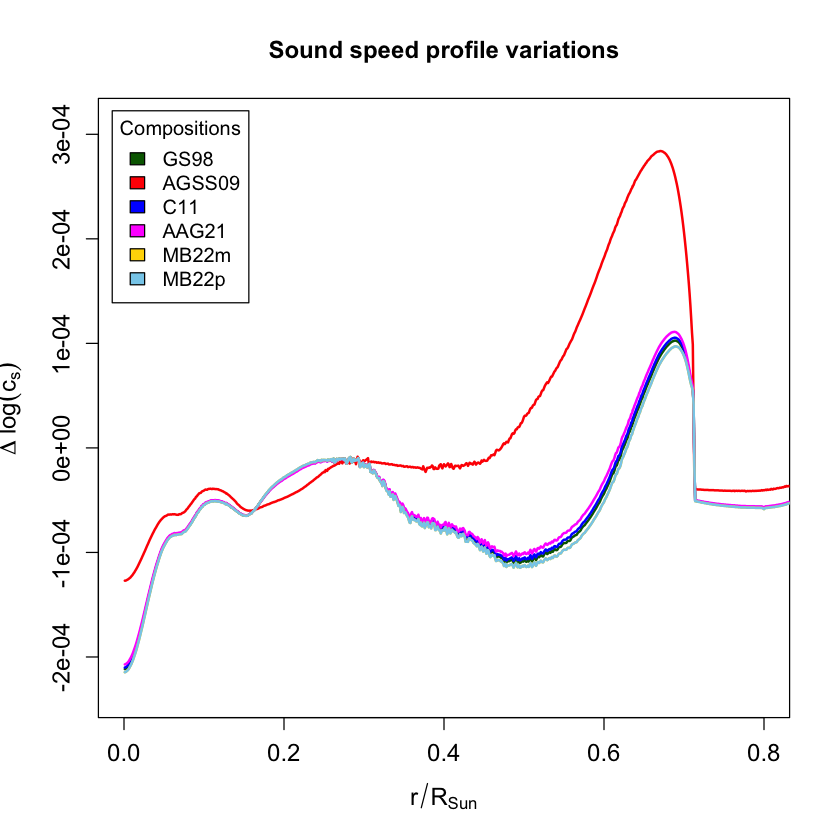

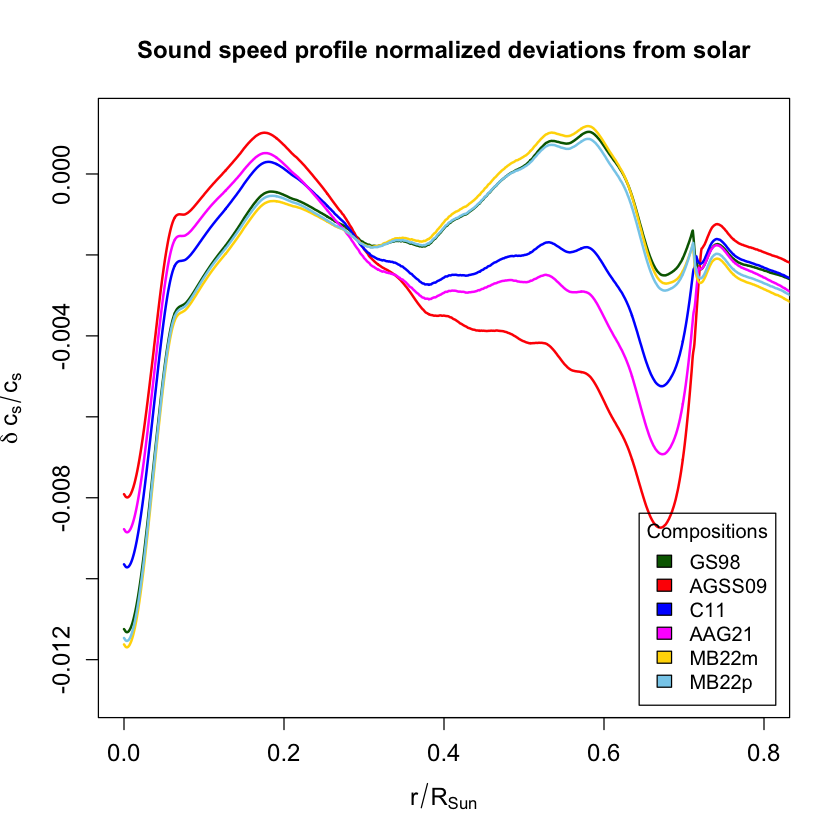

In [7]:
### DISPLAY RESULTS {{{
                 
    ### Neutrino generation rates, etc
    message(" Neutrino generation rates, surface He, and convective zone base radius")
    print(nu_new)

    ### Plots setup
    colors <- c('darkgreen','red','blue','magenta','gold', 'skyblue')

    ### Plot Cs variations for each model.
    plot_data <- Cs_var
    matplot(
	x=plot_data[,1]		,
	y=plot_data[,-1]	,
	type="l"  		,
	lwd=2  		,
	lty=1  		,
	col=colors	,
	main="Sound speed profile variations"	,
	xlim=c(0,0.8)	,
	xlab=expression(r/R[Sun])	,
	ylim=c(1.1*min(plot_data[plot_data$R_sun <0.8,-1]),1.1*max(plot_data[plot_data$R_sun <0.8,-1]))		,
	ylab=expression(Delta~log(c[s])) ,
	cex.axis = 1.2	,
	cex.lab = 1.2
	)
    legend(
	"topleft", inset=.02,
	title="Compositions",
	legend=names(plot_data[,-1]),
	fill=colors,
	horiz=FALSE,
	cex=1
	)

    ### Plot Cs deviations from solar for each model.
#     plot.new()
    plot_data <- Cs_deltas
    matplot(
	x=plot_data[,1]		,
	y=plot_data[,-1]		,
	type="l"  		,
	lwd=2  		,
	lty=1  		,
	col=colors	,
	main="Sound speed profile normalized deviations from solar"	,
	xlim=c(0,0.8)	,
	xlab=expression(r/R[Sun])	,
	ylim=c(1.1*min(plot_data[plot_data$R_sun <0.8,-1]),1.1*max(plot_data[plot_data$R_sun <0.8,-1]))		,
	ylab=expression(delta~c[s]/c[s]) ,
	cex.axis = 1.2	,
	cex.lab = 1.2
	)
    legend(
	"bottomright", inset=0.02,
	title="Compositions",
	legend=names(Cs_var[,-1]),
	fill=colors,
	horiz=FALSE,
	cex=1
	)
#     dev.off()


###}}}